<a href="https://colab.research.google.com/github/Peter0176/COU07506-labs/blob/main/COU07506_Week01_240242462943.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

- Name:PETER JACKSON LUCASI
- Registration number:240242462943
- Date:23/11/2026
- Group:6

device used
1.smartphone

For the pre-lab question, one example is a smartphone processing the audio signal picked up by its microphone.


Task 1.1 Elementary sequences

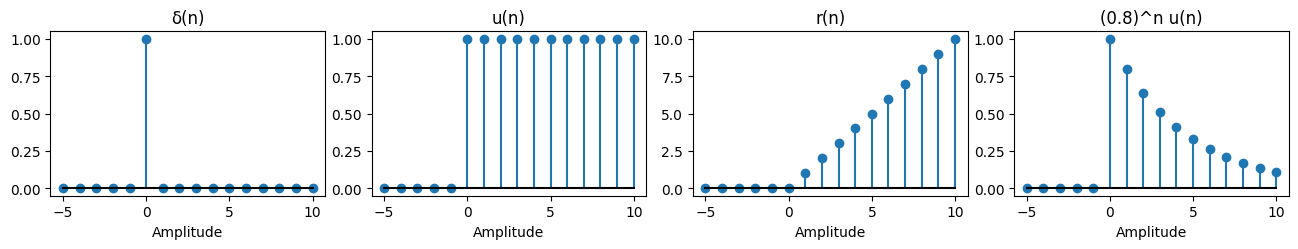

In [8]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)
step  = (n >= 0).astype(float)
ramp  = n * step
expo  = 0.8**n * step

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("Amplitude")
plt.tight_layout(); plt.show()

Task 1.2 change parameters

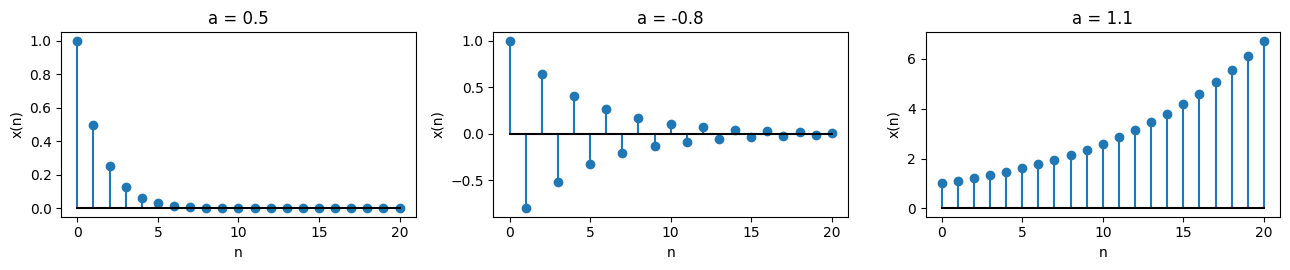

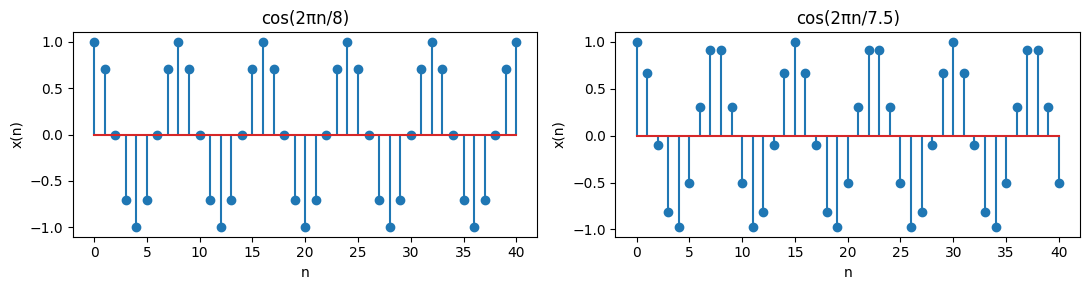

In [9]:
# part (1)
n = np.arange(0, 21)
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    ax.stem(n, a**n, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n"); ax.set_ylabel("x(n)")
plt.tight_layout(); plt.show()

# part (2)
n = np.arange(0, 41)
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].stem(n, np.cos(2*np.pi*n/8));   axes[0].set_title("cos(2πn/8)")
axes[1].stem(n, np.cos(2*np.pi*n/7.5)); axes[1].set_title("cos(2πn/7.5)")
for ax in axes:
    ax.set_xlabel("n"); ax.set_ylabel("x(n)")
plt.tight_layout(); plt.show()

Task 1.3 Audio

/tmp/ipykernel_5088/2583130439.py:6: WavFileWarning: Chunk (non-data) not understood, skipping it.
  fs, x = wavfile.read(fname)


fs = 48000 Hz, duration = 4.99 s, samples = 239688


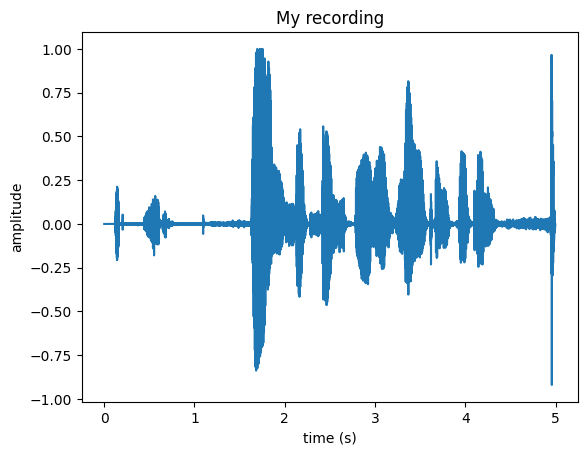

In [14]:
import os
from scipy.io import wavfile

fname = "voice_Ptt_2026-11-24_at_23_02_00.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))
else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)
t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x); plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title("My recording"); plt.show()

In [15]:
from IPython.display import Audio
Audio(x, rate=fs)

Analysis Answer

My recording has a sampling rate of 48,000 Hz. Mono audio stores one number per sample, so one minute needs numbers.

A stem plot shows the value of at each integer sample index. A continuous line connects the points and can suggest that the signal has values between the samples.

The growing exponential would violate bounded-input, bounded-output (BIBO) stability if it were the impulse response of a discrete-time LTI system. The sum of its absolute values is infinite, so even a bounded input such as a unit step would produce an output that grows without bound.